
Top Features Correlated with Price:
price                1.000000
engine_size          0.861545
curb_weight          0.820439
horsepower           0.758977
width                0.728917
length               0.683493
wheel_base           0.582379
bore                 0.531659
normalized_losses    0.136770
height               0.132613
stroke               0.084171
compression_ratio    0.075992
symboling           -0.083020
peak_rpm            -0.100589
city_mpg            -0.670766
highway_mpg         -0.693701
Name: price, dtype: float64

📊 Model Evaluation:
Mean Absolute Error (MAE): 4125.81
Mean Squared Error (MSE): 34902573.49
Root Mean Squared Error (RMSE): 5907.84
R² Score: 0.62


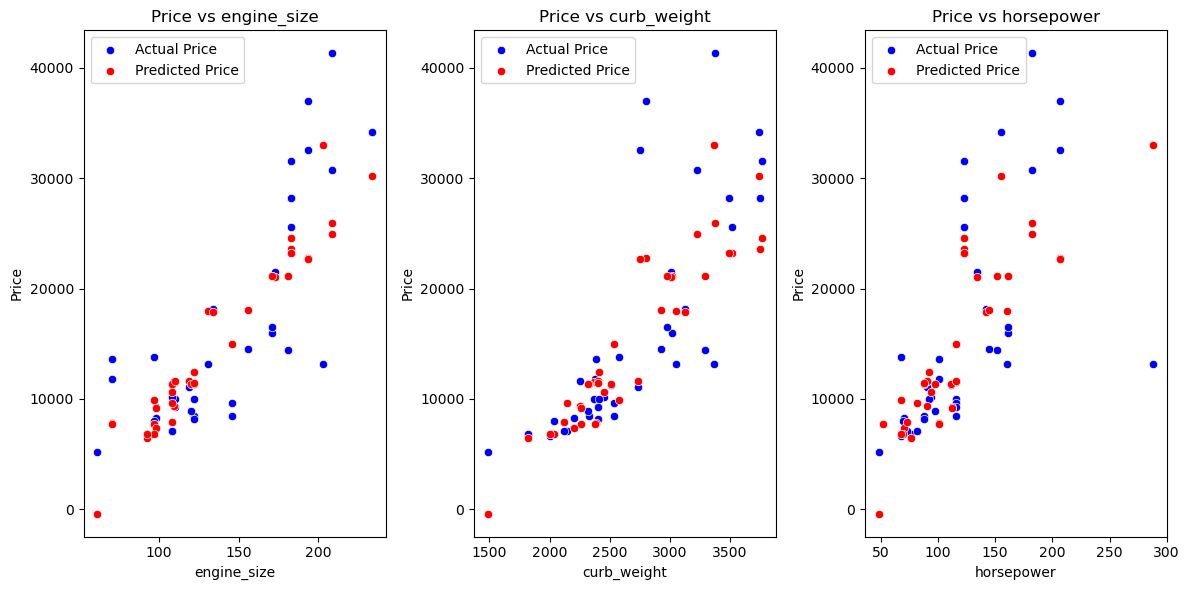

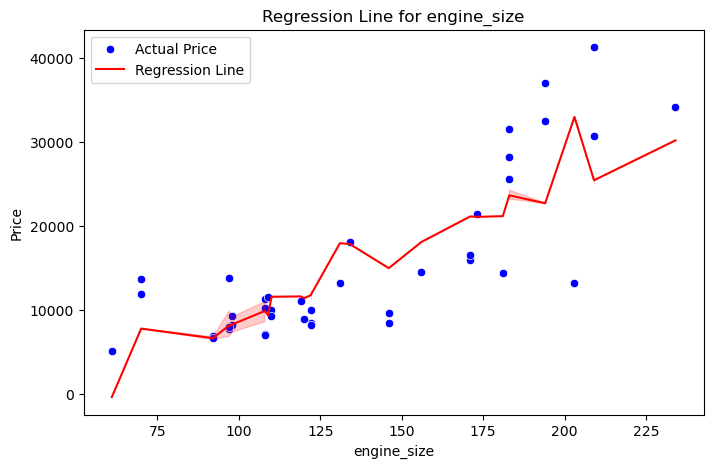


📌 Interpretation of Coefficients:
Intercept (b0): -53644.54755175081
Coefficient for engine_size: 84.48
Coefficient for curb_weight: 1.45
Coefficient for horsepower: 41.42
Coefficient for highway_mpg: 0.93
Coefficient for width: 728.15

🔍 Analysis & Limitations:
1. The R² score suggests how well the model explains price variance. If it's below 0.8, it means there are missing factors.
2. Features like brand perception, mileage, maintenance cost, and demand aren't captured in this model.
3. Linear regression assumes a linear relationship, but car prices are affected by non-linear interactions.
4. More advanced models like Random Forest or Neural Networks may capture complex dependencies better.


In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Define column names (from UCI repository)
columns = [
    "symboling", "normalized_losses", "make", "fuel_type", "aspiration",
    "num_doors", "body_style", "drive_wheels", "engine_location", "wheel_base",
    "length", "width", "height", "curb_weight", "engine_type", "num_cylinders",
    "engine_size", "fuel_system", "bore", "stroke", "compression_ratio",
    "horsepower", "peak_rpm", "city_mpg", "highway_mpg", "price"
]

# Load dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"
df = pd.read_csv(url, names=columns, na_values="?")  # Convert "?" to NaN

# Convert numerical columns to float
numeric_cols = ["normalized_losses", "bore", "stroke", "horsepower", "peak_rpm", "price"]
df[numeric_cols] = df[numeric_cols].astype(float)

# Fill missing numerical values with column mean
df.fillna(df.select_dtypes(include=[np.number]).mean(), inplace=True)

# Drop categorical columns with missing values
df.dropna(subset=["num_doors"], inplace=True)

# Convert categorical variables into dummy variables
df = pd.get_dummies(df, columns=["make", "fuel_type", "aspiration", "num_doors", "body_style",
                                 "drive_wheels", "engine_location", "engine_type", "fuel_system"], drop_first=True)

# Select features with highest correlation with price
correlation = df.select_dtypes(include=[np.number]).corr()["price"].sort_values(ascending=False)
print("\nTop Features Correlated with Price:")
print(correlation)

# Choose top features
top_features = ["engine_size", "curb_weight", "horsepower", "highway_mpg", "width"]

# Define independent (X) and dependent (y) variables
X = df[top_features]
y = df["price"]

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)

# Model evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n📊 Model Evaluation:")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.2f}")

# Visualization: Scatter plots for important features
plt.figure(figsize=(12, 6))
for i, feature in enumerate(top_features[:3]):  # Plot top 3 correlated features
    plt.subplot(1, 3, i + 1)
    sns.scatterplot(x=X_test[feature], y=y_test, label="Actual Price", color="blue")
    sns.scatterplot(x=X_test[feature], y=y_pred, label="Predicted Price", color="red")
    plt.xlabel(feature)
    plt.ylabel("Price")
    plt.title(f"Price vs {feature}")

plt.tight_layout()
plt.show()

# Regression line for the strongest correlated feature
strongest_feature = top_features[0]
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_test[strongest_feature], y=y_test, label="Actual Price", color="blue")
sns.lineplot(x=X_test[strongest_feature], y=model.predict(X_test), label="Regression Line", color="red")
plt.xlabel(strongest_feature)
plt.ylabel("Price")
plt.title(f"Regression Line for {strongest_feature}")
plt.legend()
plt.show()

# Interpret coefficients
print("\n📌 Interpretation of Coefficients:")
print("Intercept (b0):", model.intercept_)
for feature, coef in zip(top_features, model.coef_):
    print(f"Coefficient for {feature}: {coef:.2f}")

# 🔹 Analysis & Limitations
print("\n🔍 Analysis & Limitations:")
print("1. The R² score suggests how well the model explains price variance. If it's below 0.8, it means there are missing factors.")
print("2. Features like brand perception, mileage, maintenance cost, and demand aren't captured in this model.")
print("3. Linear regression assumes a linear relationship, but car prices are affected by non-linear interactions.")
print("4. More advanced models like Random Forest or Neural Networks may capture complex dependencies better.")
